In [149]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from ydata_profiling import ProfileReport
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

import warnings
warnings.filterwarnings("ignore")

print("RELEVANT PACKAGES IMPORTED!")

RELEVANT PACKAGES IMPORTED!


In [111]:
DF = pd.read_csv("Housing_Data_Lect_2.csv")
DF.head(10)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
5,10850000,7500,3,3,1,yes,no,yes,no,yes,2,yes,semi-furnished
6,10150000,8580,4,3,4,yes,no,no,no,yes,2,yes,semi-furnished
7,10150000,16200,5,3,2,yes,no,no,no,no,0,no,unfurnished
8,9870000,8100,4,1,2,yes,yes,yes,no,yes,2,yes,furnished
9,9800000,5750,3,2,4,yes,yes,no,no,yes,1,yes,unfurnished


In [94]:
DF.corr(numeric_only=True)

,price,area,bedrooms,bathrooms,stories,parking
price,1.000000,0.535997,0.366494,0.517545,0.420712,0.384394
area,0.535997,1.000000,0.151858,0.193820,0.083996,0.352980
bedrooms,0.366494,0.151858,1.000000,0.373930,0.408564,0.139270
bathrooms,0.517545,0.193820,0.373930,1.000000,0.326165,0.177496
stories,0.420712,0.083996,0.408564,0.326165,1.000000,0.045547
parking,0.384394,0.352980,0.139270,0.177496,0.045547,1.000000


In [95]:
Profile = ProfileReport(DF, title='Housing Data Report', explorative=True)
Profile.to_file('report.html')

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 13/13 [00:01<00:00, 11.72it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

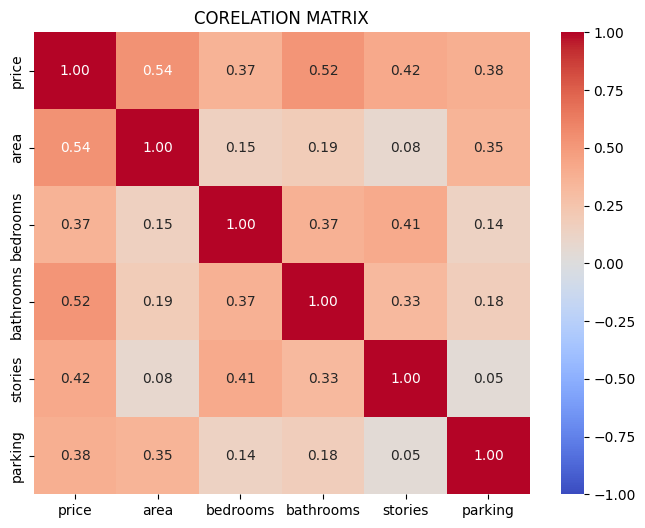

In [98]:
plt.figure(figsize=(8,6))
sns.heatmap(DF.corr(numeric_only=True),
                    annot=True,
                    cmap="coolwarm",
            fmt='.2f',
            vmin=-1, vmax=1)
plt.title("CORELATION MATRIX")
plt.show()

In [99]:
DF.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')

In [100]:
y = DF["price"]
x = DF[["area", "bedrooms", "bathrooms", "parking", "stories"]]

In [101]:
x_train, x_test, y_train, y_test, = train_test_split(x,y, random_state=42, test_size=0.2)

In [104]:
Scaler = StandardScaler()

In [108]:
x_train = Scaler.fit_transform(x_train)

In [109]:
x_test = Scaler.fit_transform(x_test)

In [112]:
lasso = Lasso()

In [114]:
lasso.fit(x_train, y_train)

,alpha,1.0
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [153]:
y_pred = lasso.predict(x_test)

In [117]:
mean_absolute_error(y_test, y_pred)

1144355.1524062408

In [155]:
mean_squared_error(y_test, y_pred)

2371522349796.4053

In [119]:
r2_score(y_test, y_pred)

0.5308162248799768

In [147]:
param_grid = {
    'alpha' : [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

In [151]:
lasso_CV = GridSearchCV(lasso, param_grid, cv=3, n_jobs=-1)

In [152]:
lasso_CV.fit(x_train, y_train)

,estimator,Lasso()
,param_grid,"{'alpha': [0.0001, 0.001, ...]}"
,scoring,None
,n_jobs,-1
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,alpha,1000


In [154]:
y_pred2 = lasso_CV.predict(x_test)

In [156]:
mean_absolute_error(y_test, y_pred)

1144355.1524062408

In [157]:
mean_squared_error(y_test, y_pred)

2371522349796.4053

In [158]:
r2_score(y_test, y_pred)

0.5308162248799768

In [159]:
lasso_CV.best_estimator_

,alpha,1000
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [161]:
lasso3 = Lasso(alpha=0.001)

In [162]:
lasso3.fit(x_train, y_train)

,alpha,0.001
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [163]:
lasso3.intercept_

np.float64(4706527.385321101)

In [164]:
lasso3.coef_

array([680058.4235683 , 112973.1852663 , 565408.61752224, 288348.77202455,
       424354.81111409])

In [126]:
model = LinearRegression()

In [127]:
model.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [128]:
print(f'intercept: {model.intercept_.round(3)}')
print(f'coefficient : {model.coef_.round(3)}')

intercept: 4706527.385
coefficient : [680058.424 112973.186 565408.618 288348.773 424354.812]


In [129]:
pd.DataFrame({
    "Variable":x.columns,
    "Coefficient": model.coef_})

,Variable,Coefficient
0,area,680058.424141
1,bedrooms,112973.185629
2,bathrooms,565408.617936
3,parking,288348.772668
4,stories,424354.811764


In [130]:
y_pred = model.predict(x_test)

In [131]:
print(y_pred[:10])

[5875043.87455568 6061686.15333072 3163300.62888426 4119830.60995304
 3298500.85009101 4224036.17317088 5477868.24566348 5244774.44945763
 3220140.56033499 2875973.85477194]


In [132]:
results = pd.DataFrame({
    "Actual":y_test,
    "Predicted":y_pred})
results.head()

,Actual,Predicted
316,4060000,5.875044e+06
77,6650000,6.061686e+06
360,3710000,3.163301e+06
90,6440000,4.119831e+06
493,2800000,3.298501e+06


In [133]:
#checking residual
print("RESIDUAL")
print("="*20)
residuals = y_test - y_pred
print(residuals.head())

RESIDUAL
316   -1.815044e+06
77     5.883138e+05
360    5.466994e+05
90     2.320169e+06
493   -4.985009e+05
Name: price, dtype: float64


In [134]:
#
results["Residual"] = residuals
results.head()

,Actual,Predicted,Residual
316,4060000,5.875044e+06,-1.815044e+06
77,6650000,6.061686e+06,5.883138e+05
360,3710000,3.163301e+06,5.466994e+05
90,6440000,4.119831e+06,2.320169e+06
493,2800000,3.298501e+06,-4.985009e+05


<function matplotlib.pyplot.xlabel(xlabel: 'str', fontdict: 'dict[str, Any] | None' = None, labelpad: 'float | None' = None, *, loc: "Literal['left', 'center', 'right'] | None" = None, **kwargs) -> 'Text'>

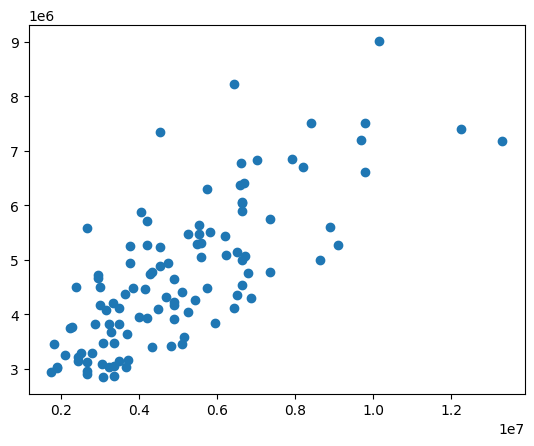

In [136]:
#check OLS assumption
plt.scatter(y_test,y_pred)
plt.xlabel

In [143]:
mse = mean_squared_error(y_test, y_pred)


In [144]:
rsme = np.sqrt(mse)
print("RMSE=" ,rmse)

RMSE= 2371521037973.701


In [146]:
r2 = r2_score(y_test, y_pred)
r2

0.5308164844119727